# FASE 5 — Modelo de Slippage

En la Fase 4 construimos un modelo básico de ejecución utilizando
correctamente Bid y Ask.

Ahora añadiremos el slippage.

El slippage es la diferencia entre:

- el precio al que esperamos ejecutar una orden;
- el precio al que finalmente se ejecuta.

En este proyecto utilizaremos la siguiente convención:

- slippage positivo = ejecución desfavorable;
- slippage cero = ejecución exactamente al precio esperado;
- slippage negativo = ejecución favorable.

Ejemplo BUY:

Precio esperado Ask = 1.16500

Con slippage adverso de 2 puntos:

Precio ejecutado = 1.16502

Ejemplo SELL:

Precio esperado Bid = 1.16500

Con slippage adverso de 2 puntos:

Precio ejecutado = 1.16498

IMPORTANTE:

Los datos actuales no contienen ejecuciones reales de órdenes.

Por tanto, el modelo de slippage de esta fase será simulado y
parametrizable.

Más adelante podrá calibrarse utilizando datos reales procedentes
del forward test en MT5.

## 1. Configuración

Utilizaremos la base de ticks limpia generada en la Fase 3.

El modelo de ejecución Bid/Ask desarrollado en la Fase 4 se
reconstruye dentro de este notebook para que la fase sea
autocontenida.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# --------------------------------------------------
# CONFIGURACIÓN
# --------------------------------------------------

DATA_PROCESSED = Path("../data/processed")

SNAPSHOT_DATE = "20260908"

TICKS_FILE = (
    DATA_PROCESSED
    / f"eurusd_ticks_clean_{SNAPSHOT_DATE}.parquet"
)


# EUR/USD con 5 decimales
POINT = 0.00001

# 10 puntos = 1 pip
POINTS_PER_PIP = 10


print("Archivo:")
print(TICKS_FILE.resolve())

print("\nPOINT:", POINT)

print(
    "Puntos por pip:",
    POINTS_PER_PIP
)

Archivo:
C:\ALL\TECNICO\TRADING\CURSOS\TUTORIAS\PROYECTO2\mt5_microstructure_lab\data\processed\eurusd_ticks_clean_20260908.parquet

POINT: 1e-05
Puntos por pip: 10


## 2. Cargar los datos

Cargamos los ticks procesados y verificamos nuevamente
que estén ordenados cronológicamente.

In [2]:
if not TICKS_FILE.exists():
    raise FileNotFoundError(
        "No existe el archivo procesado.\n"
        "Ejecute primero las fases anteriores.\n\n"
        f"{TICKS_FILE.resolve()}"
    )


ticks = pd.read_parquet(
    TICKS_FILE
)


ticks["time"] = pd.to_datetime(
    ticks["time"],
    utc=True
)


ticks = (
    ticks
    .reset_index(drop=True)
)


print(
    "Número de ticks:",
    len(ticks)
)

print(
    "Primer tick:",
    ticks["time"].min()
)

print(
    "Último tick:",
    ticks["time"].max()
)

print(
    "Orden cronológico:",
    ticks["time"].is_monotonic_increasing
)

Número de ticks: 1064157
Primer tick: 2026-09-01 00:17:05.574000+00:00
Último tick: 2026-09-08 00:16:56.458000+00:00
Orden cronológico: True


## 3. Preparar la base para ejecución

Crearemos:

- identificador de tick;
- mid-price;
- percentil 99 del spread.

El P99 continuará utilizándose únicamente como límite provisional
para nuevas entradas.

In [3]:
ticks_exec = (
    ticks
    .copy()
)


ticks_exec["tick_id"] = np.arange(
    len(ticks_exec)
)


ticks_exec["mid_price"] = (
    ticks_exec["bid"]
    +
    ticks_exec["ask"]
) / 2


spread_p99 = float(
    ticks_exec["spread_points"]
    .quantile(0.99)
)


MAX_ENTRY_SPREAD_POINTS = (
    spread_p99
)


print(
    "P99 del spread:",
    spread_p99
)

print(
    "Límite provisional de entrada:",
    MAX_ENTRY_SPREAD_POINTS
)

P99 del spread: 2.0000000000131024
Límite provisional de entrada: 2.0000000000131024


## 4. Precio esperado de ejecución

Recordamos la lógica establecida en la Fase 4.

### Posición BUY

abre comprando → Ask  
cierra vendiendo → Bid

### Posición SELL

abre vendiendo → Bid  
cierra comprando → Ask

Por tanto, de forma general:

- toda acción BUY utiliza Ask;
- toda acción SELL utiliza Bid.

In [4]:
def expected_market_price(
    tick,
    action
):
    """
    Precio esperado de una orden de mercado
    antes de aplicar slippage.

    BUY  -> Ask
    SELL -> Bid
    """

    action = action.upper()

    if action == "BUY":

        return float(
            tick["ask"]
        )

    elif action == "SELL":

        return float(
            tick["bid"]
        )

    else:

        raise ValueError(
            "action debe ser 'BUY' o 'SELL'."
        )

## 5. Convención utilizada para el slippage

Definimos:

`slippage_points > 0`

como slippage desfavorable.

### Para BUY

Un precio mayor es peor:

`precio ejecutado = Ask + slippage`

### Para SELL

Un precio menor es peor:

`precio ejecutado = Bid - slippage`

Por tanto, un slippage positivo siempre representa un deterioro de
la ejecución independientemente de que estemos comprando o vendiendo.

Un slippage negativo representará una mejora de precio.

Esta parte es fundamental.

## Función para aplicar slippage

In [5]:
def apply_slippage(
    expected_price,
    action,
    slippage_points
):
    """
    Aplica slippage al precio esperado.

    Convención:

    slippage > 0 -> desfavorable
    slippage = 0 -> sin slippage
    slippage < 0 -> favorable

    BUY:
        precio sube con slippage adverso

    SELL:
        precio baja con slippage adverso
    """

    action = action.upper()

    slippage_price = (
        slippage_points
        * POINT
    )


    if action == "BUY":

        executed_price = (
            expected_price
            +
            slippage_price
        )

    elif action == "SELL":

        executed_price = (
            expected_price
            -
            slippage_price
        )

    else:

        raise ValueError(
            "action debe ser 'BUY' o 'SELL'."
        )


    return float(
        executed_price
    )

## 6. Prueba elemental del modelo de slippage

Comprobaremos manualmente:

- BUY con slippage adverso;
- SELL con slippage adverso;
- slippage cero.

In [6]:
TEST_PRICE = 1.16500

TEST_SLIPPAGE_POINTS = 2


buy_with_slippage = apply_slippage(
    expected_price=TEST_PRICE,
    action="BUY",
    slippage_points=
        TEST_SLIPPAGE_POINTS
)


sell_with_slippage = apply_slippage(
    expected_price=TEST_PRICE,
    action="SELL",
    slippage_points=
        TEST_SLIPPAGE_POINTS
)


print(
    "Precio esperado:",
    TEST_PRICE
)

print()

print(
    "BUY con 2 puntos adversos:",
    buy_with_slippage
)

print(
    "SELL con 2 puntos adversos:",
    sell_with_slippage
)

Precio esperado: 1.165

BUY con 2 puntos adversos: 1.16502
SELL con 2 puntos adversos: 1.1649800000000001


In [7]:
assert np.isclose(
    buy_with_slippage,
    1.16502
)


assert np.isclose(
    sell_with_slippage,
    1.16498
)


assert np.isclose(
    apply_slippage(
        TEST_PRICE,
        "BUY",
        0
    ),
    TEST_PRICE
)


assert np.isclose(
    apply_slippage(
        TEST_PRICE,
        "SELL",
        0
    ),
    TEST_PRICE
)


print(
    "Pruebas básicas correctas."
)

Pruebas básicas correctas.


## 7. Simulador de una operación con slippage conocido

Primero construiremos un modelo determinista.

Le diremos explícitamente cuánto slippage existe:

- en la entrada;
- en la salida.

Esto nos permitirá verificar matemáticamente el modelo antes de
introducir aleatoriedad.

In [8]:
def simulate_trade_fixed_slippage(
    ticks_df,
    direction,
    entry_tick_id,
    exit_tick_id,
    entry_slippage_points=0.0,
    exit_slippage_points=0.0,
    max_entry_spread_points=None
):
    """
    Simula una operación completa utilizando Bid/Ask
    y slippage conocido.

    slippage positivo = adverso
    slippage negativo = favorable
    """

    direction = direction.upper()


    if direction not in {
        "BUY",
        "SELL"
    }:

        raise ValueError(
            "direction debe ser BUY o SELL."
        )


    entry_tick_id = int(
        entry_tick_id
    )

    exit_tick_id = int(
        exit_tick_id
    )


    if entry_tick_id < 0:

        raise ValueError(
            "entry_tick_id inválido."
        )


    if exit_tick_id >= len(
        ticks_df
    ):

        raise ValueError(
            "exit_tick_id fuera del rango."
        )


    if exit_tick_id < entry_tick_id:

        raise ValueError(
            "La salida no puede ocurrir "
            "antes de la entrada."
        )


    entry = ticks_df.iloc[
        entry_tick_id
    ]

    exit_ = ticks_df.iloc[
        exit_tick_id
    ]


    entry_spread = float(
        entry["spread_points"]
    )

    exit_spread = float(
        exit_["spread_points"]
    )


    # ----------------------------------------------
    # FILTRO DE SPREAD
    # ----------------------------------------------

    if (
        max_entry_spread_points
        is not None
        and
        entry_spread
        >
        max_entry_spread_points
    ):

        return {
            "status":
                "REJECTED_SPREAD",

            "direction":
                direction,

            "entry_tick_id":
                entry_tick_id,

            "entry_spread_points":
                entry_spread
        }


    # ----------------------------------------------
    # ACCIONES DE ENTRADA Y SALIDA
    # ----------------------------------------------

    if direction == "BUY":

        entry_action = "BUY"
        exit_action = "SELL"

    else:

        entry_action = "SELL"
        exit_action = "BUY"


    # ----------------------------------------------
    # PRECIOS ESPERADOS BID / ASK
    # ----------------------------------------------

    expected_entry_price = (
        expected_market_price(
            entry,
            entry_action
        )
    )


    expected_exit_price = (
        expected_market_price(
            exit_,
            exit_action
        )
    )


    # ----------------------------------------------
    # PRECIOS EJECUTADOS CON SLIPPAGE
    # ----------------------------------------------

    executed_entry_price = (
        apply_slippage(
            expected_entry_price,
            entry_action,
            entry_slippage_points
        )
    )


    executed_exit_price = (
        apply_slippage(
            expected_exit_price,
            exit_action,
            exit_slippage_points
        )
    )


    # ----------------------------------------------
    # PNL SIN SLIPPAGE
    # ----------------------------------------------

    if direction == "BUY":

        pnl_no_slippage_price = (
            expected_exit_price
            -
            expected_entry_price
        )

        pnl_with_slippage_price = (
            executed_exit_price
            -
            executed_entry_price
        )

    else:

        pnl_no_slippage_price = (
            expected_entry_price
            -
            expected_exit_price
        )

        pnl_with_slippage_price = (
            executed_entry_price
            -
            executed_exit_price
        )


    pnl_no_slippage_points = (
        pnl_no_slippage_price
        / POINT
    )


    pnl_with_slippage_points = (
        pnl_with_slippage_price
        / POINT
    )


    slippage_impact_points = (
        pnl_no_slippage_points
        -
        pnl_with_slippage_points
    )


    holding_seconds = (
        exit_["time"]
        -
        entry["time"]
    ).total_seconds()


    return {
        "status":
            "EXECUTED",

        "direction":
            direction,

        "entry_tick_id":
            entry_tick_id,

        "exit_tick_id":
            exit_tick_id,

        "entry_time":
            entry["time"],

        "exit_time":
            exit_["time"],

        "holding_seconds":
            holding_seconds,

        "entry_spread_points":
            entry_spread,

        "exit_spread_points":
            exit_spread,

        "entry_action":
            entry_action,

        "exit_action":
            exit_action,

        "expected_entry_price":
            expected_entry_price,

        "expected_exit_price":
            expected_exit_price,

        "entry_slippage_points":
            entry_slippage_points,

        "exit_slippage_points":
            exit_slippage_points,

        "executed_entry_price":
            executed_entry_price,

        "executed_exit_price":
            executed_exit_price,

        "pnl_no_slippage_points":
            pnl_no_slippage_points,

        "pnl_with_slippage_points":
            pnl_with_slippage_points,

        "slippage_impact_points":
            slippage_impact_points,

        "slippage_impact_pips":
            slippage_impact_points
            / POINTS_PER_PIP
    }

## 8. Verificar el caso sin slippage

Cuando:

`slippage = 0`

el resultado debe ser idéntico al modelo Bid/Ask de la Fase 4.

In [9]:
trade_zero_slippage = (
    simulate_trade_fixed_slippage(
        ticks_df=ticks_exec,
        direction="BUY",
        entry_tick_id=1000,
        exit_tick_id=1100,
        entry_slippage_points=0,
        exit_slippage_points=0
    )
)


display(
    pd.DataFrame(
        [trade_zero_slippage]
    ).T
)

,0
status,EXECUTED
direction,BUY
entry_tick_id,1000
exit_tick_id,1100
entry_time,2026-09-01 01:14:16.636000+00:00
exit_time,2026-09-01 01:17:24.599000+00:00
holding_seconds,187.963
entry_spread_points,2.0
exit_spread_points,1.0
entry_action,BUY


In [10]:
assert np.isclose(
    trade_zero_slippage[
        "slippage_impact_points"
    ],
    0.0,
    atol=1e-6
)


print(
    "Slippage = 0 reproduce "
    "correctamente el modelo "
    "Bid/Ask de la Fase 4."
)

Slippage = 0 reproduce correctamente el modelo Bid/Ask de la Fase 4.


## 9. Introducir slippage adverso conocido

Ahora suponemos:

- 1 punto adverso al entrar;
- 2 puntos adversos al salir.

El deterioro total esperado debe ser:

`1 + 2 = 3 puntos`

In [11]:
trade_fixed_slippage = (
    simulate_trade_fixed_slippage(
        ticks_df=ticks_exec,
        direction="BUY",
        entry_tick_id=1000,
        exit_tick_id=1100,
        entry_slippage_points=1,
        exit_slippage_points=2
    )
)


display(
    pd.DataFrame(
        [trade_fixed_slippage]
    ).T
)

,0
status,EXECUTED
direction,BUY
entry_tick_id,1000
exit_tick_id,1100
entry_time,2026-09-01 01:14:16.636000+00:00
exit_time,2026-09-01 01:17:24.599000+00:00
holding_seconds,187.963
entry_spread_points,2.0
exit_spread_points,1.0
entry_action,BUY


In [12]:
expected_impact = (
    trade_fixed_slippage[
        "entry_slippage_points"
    ]
    +
    trade_fixed_slippage[
        "exit_slippage_points"
    ]
)


observed_impact = (
    trade_fixed_slippage[
        "slippage_impact_points"
    ]
)


print(
    "Impacto esperado:",
    expected_impact,
    "puntos"
)

print(
    "Impacto observado:",
    observed_impact,
    "puntos"
)


assert np.isclose(
    observed_impact,
    expected_impact,
    atol=1e-6
)


print(
    "\nValidación correcta."
)

Impacto esperado: 3 puntos
Impacto observado: 2.999999999997449 puntos

Validación correcta.


## 10. El slippage también puede ser favorable

Aunque normalmente nos preocupa el slippage negativo para nuestra
operación, en determinados sistemas de ejecución también puede
obtenerse mejora de precio.

En nuestro modelo:

- valor positivo = adverso;
- valor negativo = favorable.

In [13]:
trade_favorable = (
    simulate_trade_fixed_slippage(
        ticks_df=ticks_exec,
        direction="BUY",
        entry_tick_id=1000,
        exit_tick_id=1100,
        entry_slippage_points=-1,
        exit_slippage_points=0
    )
)


print(
    "Impacto:",
    trade_favorable[
        "slippage_impact_points"
    ],
    "puntos"
)


display(
    pd.DataFrame(
        [trade_favorable]
    ).T
)

# Aquí deberíamos obtener aproximadamente:
# impacto = -1 punto
# Es decir, una mejora respecto a la ejecución esperada.

Impacto: -1.0000000000065512 puntos


,0
status,EXECUTED
direction,BUY
entry_tick_id,1000
exit_tick_id,1100
entry_time,2026-09-01 01:14:16.636000+00:00
exit_time,2026-09-01 01:17:24.599000+00:00
holding_seconds,187.963
entry_spread_points,2.0
exit_spread_points,1.0
entry_action,BUY


## 11. Escenarios simulados

Todavía no disponemos de datos de ejecución real suficientes para
estimar estadísticamente el slippage de nuestro futuro broker.

Por ello crearemos tres escenarios DIDÁCTICOS:

- LOW
- BASE
- STRESS

Estos parámetros NO representan estimaciones reales del broker.

Son hipótesis de simulación que posteriormente deberán ser sustituidas
o calibradas con datos reales.

El modelo supondrá que:

1. no todas las órdenes sufren slippage;
2. spreads mayores aumentan la probabilidad de slippage;
3. spreads mayores pueden producir slippage de mayor magnitud;
4. el slippage puede ser adverso o favorable;
5. el escenario STRESS representa condiciones más difíciles.

## 11. Escenarios simulados

Todavía no disponemos de datos de ejecución real suficientes para
estimar estadísticamente el slippage de nuestro futuro broker.

Por ello crearemos tres escenarios DIDÁCTICOS:

- LOW
- BASE
- STRESS

Estos parámetros NO representan estimaciones reales del broker.

Son hipótesis de simulación que posteriormente deberán ser sustituidas
o calibradas con datos reales.

El modelo supondrá que:

1. no todas las órdenes sufren slippage;
2. spreads mayores aumentan la probabilidad de slippage;
3. spreads mayores pueden producir slippage de mayor magnitud;
4. el slippage puede ser adverso o favorable;
5. el escenario STRESS representa condiciones más difíciles.

In [14]:
SLIPPAGE_SCENARIOS = {

    "LOW": {
        "base_probability": 0.03,
        "probability_per_spread_point": 0.01,
        "max_probability": 0.15,

        "poisson_lambda_base": 0.30,
        "poisson_lambda_per_spread_point": 0.05,

        "favorable_probability": 0.25,

        "max_slippage_points": 3
    },


    "BASE": {
        "base_probability": 0.08,
        "probability_per_spread_point": 0.025,
        "max_probability": 0.45,

        "poisson_lambda_base": 0.50,
        "poisson_lambda_per_spread_point": 0.10,

        "favorable_probability": 0.20,

        "max_slippage_points": 6
    },


    "STRESS": {
        "base_probability": 0.20,
        "probability_per_spread_point": 0.05,
        "max_probability": 0.80,

        "poisson_lambda_base": 1.00,
        "poisson_lambda_per_spread_point": 0.20,

        "favorable_probability": 0.10,

        "max_slippage_points": 12
    }
}


scenario_table = pd.DataFrame(
    SLIPPAGE_SCENARIOS
).T


display(
    scenario_table
)

,base_probability,probability_per_spread_point,max_probability,poisson_lambda_base,poisson_lambda_per_spread_point,favorable_probability,max_slippage_points
LOW,0.03,0.010,0.15,0.3,0.05,0.25,3.0
BASE,0.08,0.025,0.45,0.5,0.10,0.20,6.0
STRESS,0.20,0.050,0.80,1.0,0.20,0.10,12.0


Repito: estos números son supuestos de simulación, no resultados obtenidos del broker.

## 12. Generar slippage aleatorio

La función siguiente determinará:

1. si ocurre slippage;
2. su magnitud;
3. si resulta adverso o favorable.

Utilizaremos un generador aleatorio de NumPy con semilla fija para que
el experimento sea reproducible.

In [15]:
def sample_slippage_points(
    spread_points,
    rng,
    config
):
    """
    Genera slippage simulado en puntos.

    Resultado:

        > 0  adverso
        = 0  sin slippage
        < 0  favorable
    """

    spread_points = max(
        float(spread_points),
        0.0
    )


    # ----------------------------------------------
    # PROBABILIDAD DE QUE EXISTA SLIPPAGE
    # ----------------------------------------------

    probability = (
        config[
            "base_probability"
        ]
        +
        config[
            "probability_per_spread_point"
        ]
        *
        spread_points
    )


    probability = min(
        probability,
        config[
            "max_probability"
        ]
    )


    if rng.random() > probability:

        return 0


    # ----------------------------------------------
    # MAGNITUD
    # ----------------------------------------------

    lam = (
        config[
            "poisson_lambda_base"
        ]
        +
        config[
            "poisson_lambda_per_spread_point"
        ]
        *
        spread_points
    )


    magnitude = (
        1
        +
        rng.poisson(lam)
    )


    magnitude = min(
        int(magnitude),
        int(
            config[
                "max_slippage_points"
            ]
        )
    )


    # ----------------------------------------------
    # FAVORABLE O ADVERSO
    # ----------------------------------------------

    favorable = (
        rng.random()
        <
        config[
            "favorable_probability"
        ]
    )


    if favorable:

        return -magnitude

    return magnitude

## 13. Relación entre spread y probabilidad de slippage

Nuestro modelo supone que cuando el spread aumenta también empeoran
las condiciones de ejecución.

Mostraremos la probabilidad teórica de slippage del escenario BASE para
diferentes valores de spread.

In [16]:
base_config = (
    SLIPPAGE_SCENARIOS[
        "BASE"
    ]
)


spread_examples = [
    0,
    1,
    2,
    3,
    5,
    10,
    20,
    25
]


rows = []


for spread in spread_examples:

    probability = (
        base_config[
            "base_probability"
        ]
        +
        base_config[
            "probability_per_spread_point"
        ]
        *
        spread
    )


    probability = min(
        probability,
        base_config[
            "max_probability"
        ]
    )


    rows.append(
        {
            "spread_points":
                spread,

            "slippage_probability":
                probability,

            "slippage_probability_pct":
                probability * 100
        }
    )


slippage_probability_table = (
    pd.DataFrame(rows)
)


display(
    slippage_probability_table
)

,spread_points,slippage_probability,slippage_probability_pct
0,0,0.080,8.0
1,1,0.105,10.5
2,2,0.130,13.0
3,3,0.155,15.5
4,5,0.205,20.5
5,10,0.330,33.0
6,20,0.450,45.0
7,25,0.450,45.0


Esto no significa que esa sea la probabilidad real del broker.

Es la hipótesis de nuestro escenario BASE.

## 14. Simular una operación con slippage aleatorio

Integraremos ahora:

- Bid/Ask;
- filtro de spread;
- slippage de entrada;
- slippage de salida.

In [17]:
def simulate_trade_with_slippage_model(
    ticks_df,
    direction,
    entry_tick_id,
    exit_tick_id,
    rng,
    scenario="BASE",
    max_entry_spread_points=None
):
    """
    Simula una operación utilizando un modelo
    estocástico de slippage.
    """

    scenario = scenario.upper()


    if scenario not in SLIPPAGE_SCENARIOS:

        raise ValueError(
            f"Escenario desconocido: {scenario}"
        )


    entry = ticks_df.iloc[
        int(entry_tick_id)
    ]

    exit_ = ticks_df.iloc[
        int(exit_tick_id)
    ]


    entry_spread = float(
        entry["spread_points"]
    )

    exit_spread = float(
        exit_["spread_points"]
    )


    if (
        max_entry_spread_points
        is not None
        and
        entry_spread
        >
        max_entry_spread_points
    ):

        return {
            "status":
                "REJECTED_SPREAD",

            "scenario":
                scenario,

            "direction":
                direction.upper(),

            "entry_tick_id":
                int(entry_tick_id),

            "exit_tick_id":
                int(exit_tick_id),

            "entry_spread_points":
                entry_spread
        }


    config = (
        SLIPPAGE_SCENARIOS[
            scenario
        ]
    )


    entry_slippage = (
        sample_slippage_points(
            spread_points=
                entry_spread,

            rng=rng,

            config=config
        )
    )


    exit_slippage = (
        sample_slippage_points(
            spread_points=
                exit_spread,

            rng=rng,

            config=config
        )
    )


    result = (
        simulate_trade_fixed_slippage(
            ticks_df=ticks_df,

            direction=direction,

            entry_tick_id=
                entry_tick_id,

            exit_tick_id=
                exit_tick_id,

            entry_slippage_points=
                entry_slippage,

            exit_slippage_points=
                exit_slippage,

            max_entry_spread_points=
                max_entry_spread_points
        )
    )


    result[
        "scenario"
    ] = scenario


    return result

## 15. Ejemplo de operación con slippage simulado

Utilizamos una semilla fija.

Esto garantiza que si volvemos a ejecutar el notebook obtendremos
exactamente la misma secuencia aleatoria.

In [18]:
RANDOM_SEED = 20261006


rng_example = (
    np.random.default_rng(
        RANDOM_SEED
    )
)


example_trade = (
    simulate_trade_with_slippage_model(
        ticks_df=ticks_exec,

        direction="BUY",

        entry_tick_id=1000,

        exit_tick_id=1100,

        rng=rng_example,

        scenario="BASE",

        max_entry_spread_points=
            MAX_ENTRY_SPREAD_POINTS
    )
)


display(
    pd.DataFrame(
        [example_trade]
    ).T
)

,0
status,EXECUTED
direction,BUY
entry_tick_id,1000
exit_tick_id,1100
entry_time,2026-09-01 01:14:16.636000+00:00
exit_time,2026-09-01 01:17:24.599000+00:00
holding_seconds,187.963
entry_spread_points,2.0
exit_spread_points,1.0
entry_action,BUY


## 16. Experimento Monte Carlo de ejecución

Todavía no tenemos una estrategia.

Por ello NO utilizaremos estas operaciones para medir rentabilidad de
trading.

Generaremos pares de entrada/salida únicamente para estudiar:

- frecuencia del slippage;
- magnitud del slippage;
- deterioro producido en la ejecución.

La rentabilidad de estas operaciones aleatorias no tiene significado
estratégico.

Únicamente analizaremos el COSTE DE EJECUCIÓN.

In [19]:
N_TRADES = 5000

MIN_HOLD_TICKS = 50

MAX_HOLD_TICKS = 500


rng_pairs = (
    np.random.default_rng(
        RANDOM_SEED
    )
)


trade_pairs = []


max_entry_index = (
    len(ticks_exec)
    -
    MAX_HOLD_TICKS
    -
    1
)


for _ in range(N_TRADES):

    entry_id = int(
        rng_pairs.integers(
            0,
            max_entry_index
        )
    )


    holding_ticks = int(
        rng_pairs.integers(
            MIN_HOLD_TICKS,
            MAX_HOLD_TICKS + 1
        )
    )


    exit_id = (
        entry_id
        +
        holding_ticks
    )


    direction = (
        "BUY"
        if rng_pairs.random() < 0.5
        else
        "SELL"
    )


    trade_pairs.append(
        {
            "direction":
                direction,

            "entry_tick_id":
                entry_id,

            "exit_tick_id":
                exit_id,

            "holding_ticks":
                holding_ticks
        }
    )


trade_pairs_df = (
    pd.DataFrame(
        trade_pairs
    )
)


display(
    trade_pairs_df.head()
)

,direction,entry_tick_id,exit_tick_id,holding_ticks
0,BUY,777441,777856,415
1,BUY,587633,588131,498
2,BUY,998532,998829,297
3,BUY,1061891,1062207,316
4,SELL,100364,100814,450


## 17. Comparar LOW, BASE y STRESS

Utilizaremos exactamente las mismas operaciones hipotéticas en los
tres escenarios.

Así podremos comparar únicamente el efecto del slippage.

In [20]:
all_results = []


scenario_seeds = {
    "LOW": 101,
    "BASE": 202,
    "STRESS": 303
}


for scenario in [
    "LOW",
    "BASE",
    "STRESS"
]:

    rng_scenario = (
        np.random.default_rng(
            scenario_seeds[
                scenario
            ]
        )
    )


    for trade in trade_pairs:

        result = (
            simulate_trade_with_slippage_model(
                ticks_df=ticks_exec,

                direction=
                    trade["direction"],

                entry_tick_id=
                    trade[
                        "entry_tick_id"
                    ],

                exit_tick_id=
                    trade[
                        "exit_tick_id"
                    ],

                rng=rng_scenario,

                scenario=scenario,

                max_entry_spread_points=
                    MAX_ENTRY_SPREAD_POINTS
            )
        )


        all_results.append(
            result
        )


slippage_results = (
    pd.DataFrame(
        all_results
    )
)


print(
    "Resultados:",
    len(slippage_results)
)


display(
    slippage_results.head()
)

Resultados: 15000


,status,direction,entry_tick_id,exit_tick_id,entry_time,exit_time,holding_seconds,entry_spread_points,exit_spread_points,entry_action,...,expected_exit_price,entry_slippage_points,exit_slippage_points,executed_entry_price,executed_exit_price,pnl_no_slippage_points,pnl_with_slippage_points,slippage_impact_points,slippage_impact_pips,scenario
0,EXECUTED,BUY,777441,777856,2026-09-04 14:13:19.234000+00:00,2026-09-04 14:18:00.392000+00:00,281.158,0.0,1.0,BUY,...,1.16217,0.0,0.0,1.16220,1.16217,-3.0,-3.0,0.0,0.0,LOW
1,EXECUTED,BUY,587633,588131,2026-09-03 15:54:56.821000+00:00,2026-09-03 15:55:51.430000+00:00,54.609,1.0,0.0,BUY,...,1.16294,0.0,0.0,1.16288,1.16294,6.0,6.0,0.0,0.0,LOW
2,EXECUTED,BUY,998532,998829,2026-09-07 12:27:33.524000+00:00,2026-09-07 12:29:01.402000+00:00,87.878,0.0,1.0,BUY,...,1.16245,0.0,0.0,1.16245,1.16245,0.0,0.0,0.0,0.0,LOW
3,EXECUTED,BUY,1061891,1062207,2026-09-07 23:14:33.957000+00:00,2026-09-07 23:23:21.194000+00:00,527.237,2.0,0.0,BUY,...,1.16225,0.0,0.0,1.16221,1.16225,4.0,4.0,0.0,0.0,LOW
4,EXECUTED,SELL,100364,100814,2026-09-01 14:47:05.193000+00:00,2026-09-01 14:50:33.286000+00:00,208.093,1.0,0.0,SELL,...,1.15940,0.0,0.0,1.15947,1.15940,7.0,7.0,0.0,0.0,LOW


## Separar operaciones ejecutadas

In [21]:
executed_results = (
    slippage_results[
        slippage_results[
            "status"
        ]
        ==
        "EXECUTED"
    ]
    .copy()
)


rejected_results = (
    slippage_results[
        slippage_results[
            "status"
        ]
        ==
        "REJECTED_SPREAD"
    ]
    .copy()
)


print(
    "Ejecutadas:",
    len(executed_results)
)

print(
    "Rechazadas por spread:",
    len(rejected_results)
)

Ejecutadas: 14919
Rechazadas por spread: 81


## 18. Medir el coste producido por el slippage

La variable principal será:

`slippage_impact_points`

Interpretación:

- > 0 → empeoró la operación;
- = 0 → no cambió la ejecución;
- < 0 → mejoró la ejecución.

In [22]:
summary_rows = []


for scenario in [
    "LOW",
    "BASE",
    "STRESS"
]:

    df = executed_results[
        executed_results[
            "scenario"
        ]
        ==
        scenario
    ]


    impact = (
        df[
            "slippage_impact_points"
        ]
    )


    unchanged = np.isclose(
        impact,
        0.0,
        atol=1e-9
    )


    worsened = (
        impact > 1e-9
    )


    improved = (
        impact < -1e-9
    )


    summary_rows.append(
        {
            "scenario":
                scenario,

            "trades":
                len(df),

            "mean_impact_points":
                impact.mean(),

            "median_impact_points":
                impact.median(),

            "p95_impact_points":
                impact.quantile(0.95),

            "max_impact_points":
                impact.max(),

            "pct_unchanged":
                unchanged.mean()
                * 100,

            "pct_worsened":
                worsened.mean()
                * 100,

            "pct_improved":
                improved.mean()
                * 100
        }
    )


slippage_summary = (
    pd.DataFrame(
        summary_rows
    )
)


display(
    slippage_summary
)

,scenario,trades,mean_impact_points,median_impact_points,p95_impact_points,max_impact_points,pct_unchanged,pct_worsened,pct_improved
0,LOW,4973,0.045848,0.0,1.0,4.0,93.062538,5.127690,1.809773
1,BASE,4973,0.160668,0.0,2.0,6.0,84.094108,12.587975,3.317917
2,STRESS,4973,0.699779,0.0,4.0,9.0,60.768148,34.908506,4.323346


## Convertir el coste a pips

In [23]:
slippage_summary[
    "mean_impact_pips"
] = (
    slippage_summary[
        "mean_impact_points"
    ]
    /
    POINTS_PER_PIP
)


slippage_summary[
    "p95_impact_pips"
] = (
    slippage_summary[
        "p95_impact_points"
    ]
    /
    POINTS_PER_PIP
)


display(
    slippage_summary
)

,scenario,trades,mean_impact_points,median_impact_points,p95_impact_points,max_impact_points,pct_unchanged,pct_worsened,pct_improved,mean_impact_pips,p95_impact_pips
0,LOW,4973,0.045848,0.0,1.0,4.0,93.062538,5.127690,1.809773,0.004585,0.1
1,BASE,4973,0.160668,0.0,2.0,6.0,84.094108,12.587975,3.317917,0.016067,0.2
2,STRESS,4973,0.699779,0.0,4.0,9.0,60.768148,34.908506,4.323346,0.069978,0.4


## 19. Distribución del slippage por orden

Analizaremos por separado el slippage observado en:

- entrada;
- salida.

Esto será útil posteriormente cuando comparemos nuestro modelo con
ejecuciones reales de MT5.

In [24]:
base_results = (
    executed_results[
        executed_results[
            "scenario"
        ]
        ==
        "BASE"
    ]
    .copy()
)


entry_slippage_summary = (
    base_results[
        "entry_slippage_points"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "slippage_points"
    )
    .to_frame(
        "frequency"
    )
)


entry_slippage_summary[
    "percentage"
] = (
    entry_slippage_summary[
        "frequency"
    ]
    /
    len(base_results)
    *
    100
)


display(
    entry_slippage_summary
)

,frequency,percentage
slippage_points,,
-4.0,4,0.080434
-3.0,4,0.080434
-2.0,24,0.482606
-1.0,45,0.904886
0.0,4578,92.057108
1.0,177,3.559220
2.0,103,2.071184
3.0,29,0.583149
4.0,7,0.140760


## 20. Analizar slippage según el spread

Nuestro escenario supone que el riesgo de slippage aumenta cuando
las condiciones de spread empeoran.

Agruparemos las operaciones según el spread de entrada.

In [25]:
base_results[
    "entry_spread_group"
] = pd.cut(

    base_results[
        "entry_spread_points"
    ],

    bins=[
        -0.01,
        0,
        1,
        2,
        5,
        10,
        np.inf
    ],

    labels=[
        "0",
        "0-1",
        "1-2",
        "2-5",
        "5-10",
        ">10"
    ]
)


slippage_by_spread = (
    base_results
    .groupby(
        "entry_spread_group",
        observed=False
    )
    .agg(
        trades=(
            "slippage_impact_points",
            "size"
        ),

        mean_impact_points=(
            "slippage_impact_points",
            "mean"
        ),

        p95_impact_points=(
            "slippage_impact_points",
            lambda x:
                x.quantile(0.95)
        )
    )
)


display(
    slippage_by_spread
)

,trades,mean_impact_points,p95_impact_points
entry_spread_group,,,
0,2767,0.142031,2.00
0-1,605,0.138843,2.00
1-2,1559,0.196280,2.00
2-5,42,0.380952,1.95
5-10,0,NaN,NaN
>10,0,NaN,NaN


Hay una particularidad: como estamos bloqueando nuevas entradas con spread superior a P99, probablemente los grupos superiores quedarán sin operaciones ejecutadas.

Eso es correcto.

## 21. Comparar el coste medio entre escenarios

Representamos el deterioro medio producido por el slippage.

Esta gráfica no representa rentabilidad de una estrategia.

Representa únicamente coste adicional de ejecución.

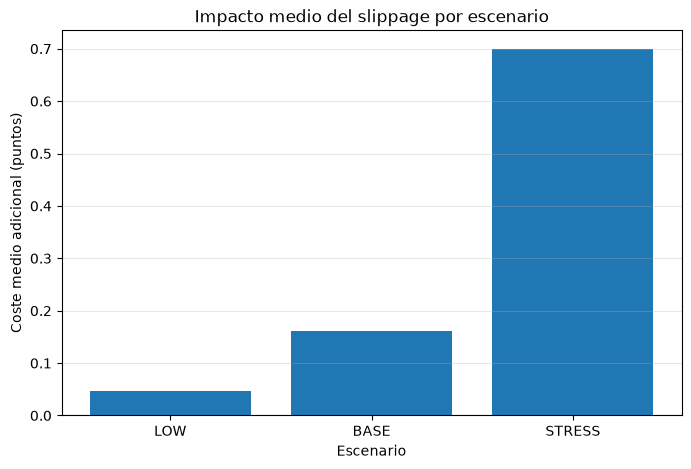

In [26]:
plt.figure(
    figsize=(8, 5)
)


plt.bar(
    slippage_summary[
        "scenario"
    ],

    slippage_summary[
        "mean_impact_points"
    ]
)


plt.title(
    "Impacto medio del slippage por escenario"
)

plt.xlabel(
    "Escenario"
)

plt.ylabel(
    "Coste medio adicional (puntos)"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

## 22. Distribución del coste de slippage

Observamos la distribución del impacto total sobre cada operación
en el escenario BASE.

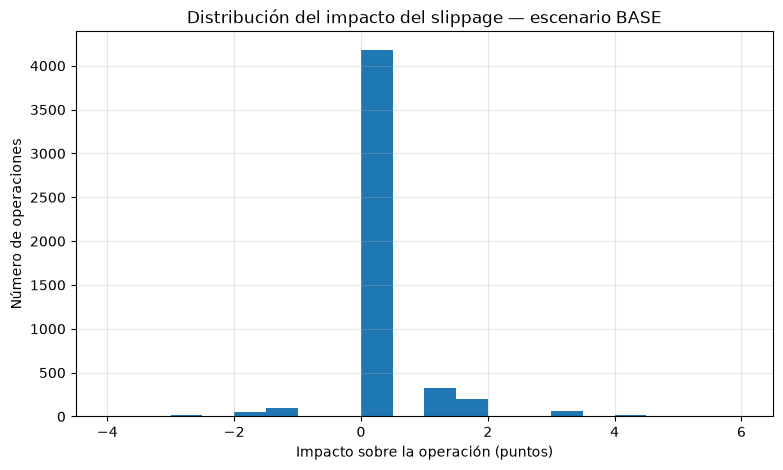

In [27]:
plt.figure(
    figsize=(9, 5)
)


plt.hist(
    base_results[
        "slippage_impact_points"
    ],
    bins=20
)


plt.title(
    "Distribución del impacto del slippage — escenario BASE"
)

plt.xlabel(
    "Impacto sobre la operación (puntos)"
)

plt.ylabel(
    "Número de operaciones"
)

plt.grid(
    alpha=0.3
)

plt.show()

## 23. Resumen de la Fase 5

In [28]:
phase5_summary = pd.DataFrame(
    [
        {
            "concepto":
                "Ticks disponibles",

            "valor":
                len(ticks_exec)
        },

        {
            "concepto":
                "P99 spread",

            "valor":
                spread_p99
        },

        {
            "concepto":
                "BUY adverso",

            "valor":
                "precio ejecutado > Ask esperado"
        },

        {
            "concepto":
                "SELL adverso",

            "valor":
                "precio ejecutado < Bid esperado"
        },

        {
            "concepto":
                "Slippage positivo",

            "valor":
                "desfavorable"
        },

        {
            "concepto":
                "Slippage negativo",

            "valor":
                "favorable"
        },

        {
            "concepto":
                "Slippage real observado",

            "valor":
                "NO disponible todavía"
        },

        {
            "concepto":
                "Modelo actual",

            "valor":
                "simulado / parametrizable"
        },

        {
            "concepto":
                "Latencia",

            "valor":
                "NO incluida todavía"
        }
    ]
)


display(
    phase5_summary
)

,concepto,valor
0,Ticks disponibles,1064157
1,P99 spread,2.0
2,BUY adverso,precio ejecutado > Ask esperado
3,SELL adverso,precio ejecutado < Bid esperado
4,Slippage positivo,desfavorable
5,Slippage negativo,favorable
6,Slippage real observado,NO disponible todavía
7,Modelo actual,simulado / parametrizable
8,Latencia,NO incluida todavía


# Conclusión de la Fase 5

En esta fase hemos incorporado el slippage al modelo de ejecución.

El modelo ahora diferencia entre:

1. precio esperado;
2. precio realmente simulado de ejecución.

Convención utilizada:

- slippage positivo = ejecución desfavorable;
- slippage cero = ejecución esperada;
- slippage negativo = mejora de precio.

Para BUY:

`precio ejecutado = Ask esperado + slippage`

Para SELL:

`precio ejecutado = Bid esperado - slippage`

También verificamos matemáticamente que el deterioro total de una
operación corresponde a la suma del slippage de entrada y salida.

Se construyeron tres escenarios:

- LOW;
- BASE;
- STRESS.

IMPORTANTE:

Estos escenarios no representan todavía el comportamiento real de un
broker.

Son hipótesis para estudiar cómo afecta la calidad de ejecución a una
estrategia.

Posteriormente deberán calibrarse utilizando ejecuciones reales
registradas desde MT5.

El modelo ahora incluye:

- Bid / Ask;
- spread;
- filtro de spread;
- slippage.

Todavía falta incorporar:

- latencia;
- comisiones;
- swap.

La siguiente fase será:

`06_latency_model.ipynb`